# Effluent BOD on the day, not five days later: a soft sensor on real treatment-plant data

**KAI Water & Energy case studies** · [Interactive version on the KAI platform](https://hydro-saas.charkaks0.workers.dev/demo/reference/soft-sensor) · [Start free](https://hydro-saas.charkaks0.workers.dev/portal?plan=hydrosaas:free)

Outlet **BOD5** is the compliance number for most effluent permits (NEMA 2020 in Uganda sets 50 mg/L), and it
takes **five days** in the laboratory. By the time a breach is known, the water left the plant days ago. A
*soft sensor* estimates it on the day from something measured fast, here the outlet suspended solids that a
turbidity probe reads continuously.

In this notebook you will:

1. load 22 months of real daily data from an urban wastewater treatment plant (1990–1991);
2. see how outlet BOD5 follows outlet suspended solids;
3. build a soft sensor that is **retrained as lab results arrive** and only uses what was known on the day;
4. test it on 1991 against every real lab result, and against what an operator has without it: the last
   lab result, at least five days old;
5. compare with KAI's engine, which also tests richer probe sets.

Runtime: under a minute.

## The data

**UCI Machine Learning Repository, *Water Treatment Plant* (dataset 106).** Creator: Manel Poch, Unitat
d'Enginyeria Química, Universitat Autònoma de Barcelona; donors Javier Béjar and Ulises Cortés, Universitat
Politècnica de Catalunya (1993). Licence **CC BY 4.0**. File `water-treatment.data`, vendored unchanged in
`data/` (SHA-256 `af2e632b…98a7a8a`).

527 days of daily measurements at the plant inlet (`-E`), primary settler (`-P`), secondary settler (`-D`) and
outlet (`-S`): flow, pH, BOD5 (`DBO`), COD (`DQO`), suspended solids (`SS`), sediments and conductivity. Missing
values are `?`.

In [1]:
import hashlib
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

F = Path("data/water-treatment.data")
assert hashlib.sha256(F.read_bytes()).hexdigest() == "af2e632b370646ea9763b11aed54b30423f0c3b8a7fb1b7d23e1c922098a7a8a"
COLUMNS = ("Q-E ZN-E PH-E DBO-E DQO-E SS-E SSV-E SED-E COND-E PH-P DBO-P SS-P SSV-P SED-P COND-P PH-D DBO-D DQO-D "
           "SS-D SSV-D SED-D COND-D PH-S DBO-S DQO-S SS-S SSV-S SED-S COND-S RD-DBO-P RD-SS-P RD-SED-P RD-DBO-S "
           "RD-DQO-S RD-DBO-G RD-DQO-G RD-SS-G RD-SED-G").split()
df = pd.read_csv(F, header=None, names=["day", *COLUMNS], na_values="?").dropna(subset=["day"])
df["date"] = pd.to_datetime(df["day"].str[2:], format="%d/%m/%y")
df = df.drop(columns="day").set_index("date").sort_index()
LIMIT, WARN, LAG = 50.0, 40.0, 5          # NEMA 2020 BOD5 limit (mg/L), warning level, lab delay (days)
d = df[["DBO-S", "SS-S", "DQO-S"]].rename(columns={"DBO-S": "BOD", "SS-S": "TSS", "DQO-S": "COD"})
print(f"{len(df)} days, {df.index.min():%d %b %Y} to {df.index.max():%d %b %Y}; {d.BOD.notna().sum()} outlet BOD5 results")

527 days, 01 Jan 1990 to 30 Oct 1991; 504 outlet BOD5 results


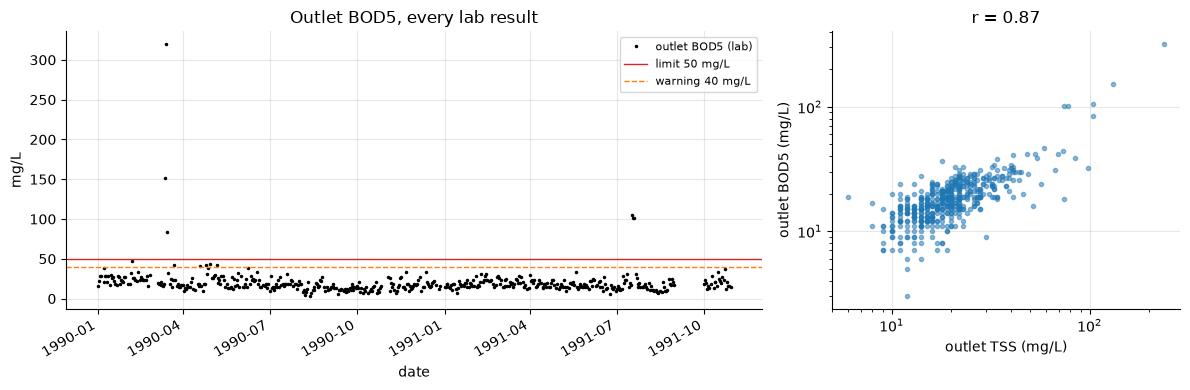

In [2]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
d.BOD.plot(ax=a1, style=".", ms=3, color="k", label="outlet BOD5 (lab)")
a1.axhline(LIMIT, color="tab:red", lw=1, label="limit 50 mg/L"); a1.axhline(WARN, color="tab:orange", lw=1, ls="--", label="warning 40 mg/L")
a1.set(ylabel="mg/L", title="Outlet BOD5, every lab result"); a1.legend(fontsize=8)
ok = d[["BOD", "TSS"]].dropna()
a2.loglog(ok.TSS, ok.BOD, ".", alpha=0.5)
a2.set(xlabel="outlet TSS (mg/L)", ylabel="outlet BOD5 (mg/L)", title=f"r = {np.corrcoef(ok.TSS, ok.BOD)[0, 1]:.2f}")
plt.tight_layout()

Most days are well below the limit; a few spikes are not, and those are the days that matter. Outlet BOD5
rises with outlet suspended solids roughly as a power law, a straight line on log axes.

## The soft sensor, tested honestly

Walk forward through the record, one sampled day at a time. On day *t*:

* the model may only use lab results dated **five days or more** before *t* (that is when they are known);
* it is refitted once a week on everything known by then: log(BOD) as a straight line of log(1 + TSS), with
  Duan's smearing correction when converting back;
* it predicts today's BOD5 from today's outlet TSS;
* its 90 % band comes from the errors it made on earlier days whose lab results are now known.

The first nine months (April–December 1990) only warm it up. **1991 is the test**: every prediction made there
is compared with the real lab result.

In [3]:
def walk_forward(feature="TSS", start="1990-04-01", refit_every=7, min_train=60):
    data = d.dropna(subset=["BOD", feature])
    rows, coef, last_fit = [], None, None
    for t in data.index[data.index >= start]:
        known = data[data.index <= t - pd.Timedelta(days=LAG)]
        if len(known) < min_train:
            continue
        if coef is None or (t - last_fit).days >= refit_every:
            A = np.column_stack([np.ones(len(known)), np.log1p(known[feature])])
            ly = np.log(known.BOD.clip(lower=0.1))
            coef, *_ = np.linalg.lstsq(A, ly, rcond=None)
            smear = np.mean(np.exp(ly - A @ coef))            # Duan's correction for predicting on logs
            last_fit = t
        pred = max(1.0, float(np.exp(coef[0] + coef[1] * np.log1p(data.at[t, feature])) * smear))
        past = [r["obs"] / r["pred"] for r in rows if r["date"] <= t - pd.Timedelta(days=LAG)]
        lo, hi = (np.quantile(past, [0.05, 0.95]) * pred) if len(past) >= 40 else (np.nan, np.nan)
        rows.append({"date": t, "pred": pred, "lo": lo, "hi": hi, "obs": data.at[t, "BOD"]})
    return pd.DataFrame(rows).set_index("date")

wf = walk_forward()
last = d.BOD.dropna()
last_known = pd.Series({t: last[last.index <= t - pd.Timedelta(days=LAG)].iloc[-1] for t in wf.index if (last.index <= t - pd.Timedelta(days=LAG)).any()})
test = wf.loc["1991":]

def score(pred, obs):
    e = (pred - obs).dropna()
    hit = obs > WARN
    return {"MAE (mg/L)": e.abs().mean(), "within 25 %": ((pred - obs).abs() <= 0.25 * obs).mean(),
            "days above 40 mg/L flagged on the day": f"{int((pred[hit] > WARN).sum())} of {int(hit.sum())}",
            "false alarms": int(((pred > WARN) & ~hit).sum())}

median_known = pd.Series({t: last[last.index <= t - pd.Timedelta(days=LAG)].median() for t in test.index})
print(f"1991 test: {len(test)} lab days with both outlet BOD5 and TSS")
pd.DataFrame({
    "soft sensor (TSS probe)": score(test.pred, test.obs),
    "last lab result (5+ days old)": score(last_known.reindex(test.index), test.obs),
    "typical value (median of known results)": score(median_known, test.obs),
}).T.style.format({"MAE (mg/L)": "{:.1f}", "within 25 %": "{:.0%}"})

1991 test: 224 lab days with both outlet BOD5 and TSS


,MAE (mg/L),within 25 %,days above 40 mg/L flagged on the day,false alarms
soft sensor (TSS probe),4.4,69%,3 of 3,1
last lab result (5+ days old),7.4,52%,0 of 3,4
typical value (median of known results),5.5,61%,0 of 3,0


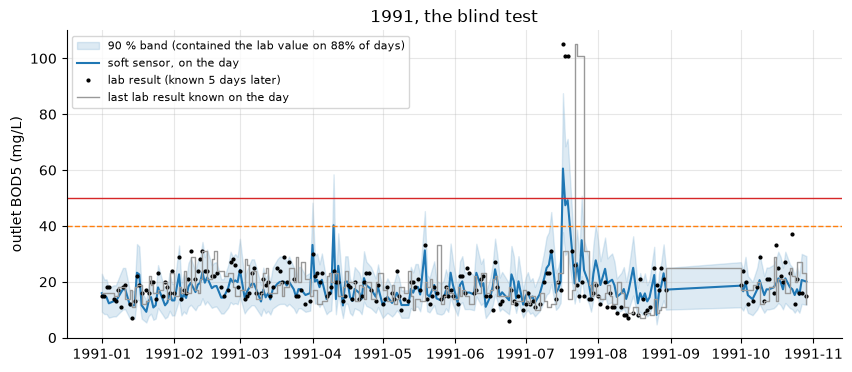

In [4]:
cover = ((test.obs >= test.lo) & (test.obs <= test.hi)).mean()
fig, ax = plt.subplots()
ax.fill_between(test.index, test.lo, test.hi, color="tab:blue", alpha=0.15, label=f"90 % band (contained the lab value on {cover:.0%} of days)")
ax.plot(test.index, test.pred, color="tab:blue", label="soft sensor, on the day")
ax.plot(test.index, test.obs, "k.", ms=4, label="lab result (known 5 days later)")
ax.step(test.index, last_known.reindex(test.index), where="post", color="0.6", lw=1, label="last lab result known on the day")
ax.axhline(LIMIT, color="tab:red", lw=1); ax.axhline(WARN, color="tab:orange", lw=1, ls="--")
ax.set(ylabel="outlet BOD5 (mg/L)", title="1991, the blind test"); ax.legend(fontsize=8, loc="upper left");

,soft sensor,band low,band high,lab BOD5,last lab result known,inside 90 % band
date,,,,,,
1991-07-17,60.6,37.7,87.5,105.0,31.0,False
1991-07-18,47.4,29.5,68.5,101.0,31.0,False
1991-07-19,49.2,30.8,71.1,101.0,14.0,False


False alarms in 1991 (soft sensor above 40 mg/L, lab below): 1 ['10 Apr']


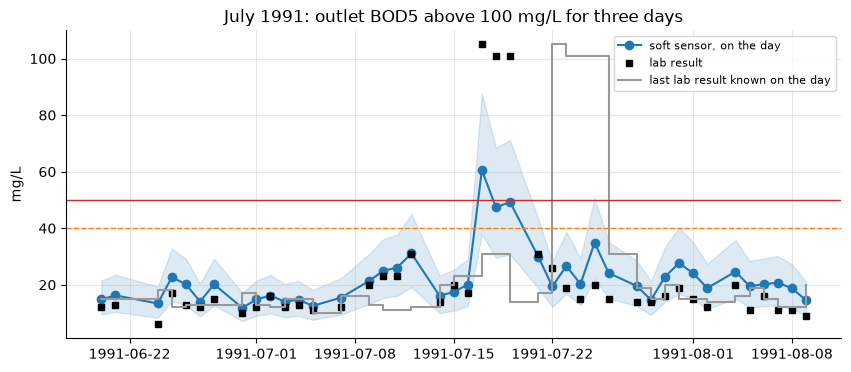

In [5]:
july = test.loc["1991-06-20":"1991-08-10"]
fig, ax = plt.subplots()
ax.fill_between(july.index, july.lo, july.hi, color="tab:blue", alpha=0.15)
ax.plot(july.index, july.pred, "o-", color="tab:blue", label="soft sensor, on the day")
ax.plot(july.index, july.obs, "ks", ms=5, label="lab result")
ax.step(july.index, last_known.reindex(july.index), where="post", color="0.6", label="last lab result known on the day")
ax.axhline(WARN, color="tab:orange", lw=1, ls="--"); ax.axhline(LIMIT, color="tab:red", lw=1)
ax.set(title="July 1991: outlet BOD5 above 100 mg/L for three days", ylabel="mg/L"); ax.legend(fontsize=8);
ev = test[test.obs > WARN].assign(**{"last lab result known": last_known.reindex(test[test.obs > WARN].index),
                                    "inside 90 % band": lambda x: (x.obs >= x.lo) & (x.obs <= x.hi)})
display(ev.rename(columns={"obs": "lab BOD5", "pred": "soft sensor", "lo": "band low", "hi": "band high"}).round(1))
fa = test[(test.pred > WARN) & (test.obs <= WARN)]
print(f"False alarms in 1991 (soft sensor above 40 mg/L, lab below): {len(fa)}", list(fa.index.strftime("%d %b")))

In mid-July 1991 outlet BOD5 jumped above 100 mg/L for three days. The soft sensor rose above the 40 mg/L
warning level **on each of those days**, because outlet suspended solids rose with it, while the last known lab
result still said all was well. It did not see how bad it was: it estimated about 50–60 mg/L against a lab value
near 100, crossed the 50 mg/L limit on only one of the three days, and the lab value fell outside its band on the
last two. A soft sensor tells you *when to call the lab*; it does not replace it.

## Compare with the KAI engine

KAI's engine runs the same test with more care (it also chooses the model form on 1990 data only, and uses a
proper conformal band), and tries richer probe sets. Its results, from `results/kai_engine_results.json`:

In [6]:
kai = json.loads(Path("results/kai_engine_results.json").read_text())
assert abs(score(test.pred, test.obs)["MAE (mg/L)"] - kai["tiers"][0]["mae"]) < 0.2, "MAE differs from the published KAI result"
rows = [{"inputs": t["label"], "model": t["model"], "MAE (mg/L)": t["mae"], "within 25 %": t["within_25pct"],
         "days above 40 flagged": f"{t['above_40']['caught']} of {t['above_40']['days']}", "band contained the lab value": t["coverage"]} for t in kai["tiers"]]
for k, b in kai["baselines"].items():
    rows.append({"inputs": b["label"], "model": "baseline", "MAE (mg/L)": b["mae"], "within 25 %": b["within_25pct"],
                 "days above 40 flagged": f"{b['above_40']['caught']} of {b['above_40']['days']}", "band contained the lab value": np.nan})
rows.insert(0, {"inputs": "This notebook: TSS probe", "model": "power law", "MAE (mg/L)": score(test.pred, test.obs)["MAE (mg/L)"],
                "within 25 %": score(test.pred, test.obs)["within 25 %"], "days above 40 flagged": score(test.pred, test.obs)["days above 40 mg/L flagged on the day"], "band contained the lab value": cover})
print(f"The engine scores {kai['n_test']} lab days of 1991; this notebook {len(test)} (it needs both BOD5 and TSS on the day).")
pd.DataFrame(rows).style.format({"MAE (mg/L)": "{:.1f}", "within 25 %": "{:.0%}", "band contained the lab value": "{:.0%}"}, na_rep="").hide(axis="index")

The engine scores 226 lab days of 1991; this notebook 224 (it needs both BOD5 and TSS on the day).


inputs,model,MAE (mg/L),within 25 %,days above 40 flagged,band contained the lab value
This notebook: TSS probe,power law,4.4,69%,3 of 3,88%
Turbidity / TSS probe,loglog,4.4,69%,3 of 3,88%
Four online probes,loglog,4.5,69%,3 of 3,87%
TSS probe + 2-hour COD,loglog,4.3,66%,3 of 3,88%
Last lab result (5+ days old),baseline,7.5,52%,0 of 3,
Typical value (median of past results),baseline,5.5,61%,0 of 3,


**What this means for a factory or a park:** a turbidity probe at the outlet, read through a soft sensor that
keeps learning from the lab, turns a five-day-old compliance number into a same-day estimate with a band, and
raises the alarm on the day a failure starts, while there is still time to act. The lab stays the reference; the soft sensor
decides when to call it.

---

**On the KAI platform**

* [Soft-sensor case, interactive](https://hydro-saas.charkaks0.workers.dev/demo/reference/soft-sensor): the full 1991 test, day by day.
* [HydroSaaS factory compliance demo](https://hydro-saas.charkaks0.workers.dev/demo): outlets checked against the NEMA 2020 limits.
* [Effluent compliance and pollution tracing](https://kai-water.charkaks0.workers.dev/solution-effluent-compliance.html) · [Start free](https://hydro-saas.charkaks0.workers.dev/portal?plan=hydrosaas:free) · [Talk to us](https://kai-water.charkaks0.workers.dev/contact.html)

*Code: MIT. Text and figures: CC BY 4.0, KAI Water & Energy. Data: UCI Water Treatment Plant dataset (M. Poch, UAB; J. Béjar and U. Cortés, UPC), CC BY 4.0.*